# Evaluate the released models

Evaluates the released models in `models/` on their test splits:

- **Training data:** a model trained on web images only vs one trained on a 50:50 mix of web and laboratory images
- **Architectures:** STD, CONCAT, GATED and ATT, compared on precision, recall, accuracy and the taxonomic alignment score (TAS), with paired McNemar tests
- **Error vs genus richness:** species-level error of GATED against the number of species in each genus
- **Saliency maps:** which pixels drive GATED's species prediction on example images

Results can vary by about 0.1-0.2 points across GPUs and platforms.

Needs `paper_catalog.csv`, `mixcompare_catalog.csv` and the test images they list (see the README). For the saliency maps, it uses the example photos in `images/` at the repo root.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from scipy.stats import binomtest, chi2
from sklearn.metrics import recall_score

from cryptovision import train
from cryptovision.data import load_catalogs, make_parent_lists, split_data, tensorflow_dataset
from cryptovision.predict import CryptoVisionAI
from cryptovision.weights import MODELS_DIR, SETTINGS, class_names, load_pretrained

CATALOG = "path_to/catalog.csv"            # architecture comparison, error vs richness
MIX_CATALOG = "path_to/mixcompare_catalog.csv"   # web-only vs mixed
SALIENCY_DIR = Path("../images")                 # example photos for the saliency maps

ARCHITECTURES = ["STD", "CONCAT", "GATED", "ATT"]
LEVELS = ["family", "genus", "species"]
METRICS = {"precision": "Precision", "recall": "Recall", "accuracy": "Accuracy", "tas": "TAS"}

cfg = yaml.safe_load(SETTINGS.read_text())
cfg["data"]["catalog"] = [CATALOG]
train.setup_tf(cfg["general"])   # must run before TensorFlow touches the GPU
released = json.loads((MODELS_DIR / "manifest.json").read_text())["models"]

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Training data: web-only vs mixed

Both models are evaluated on the test split of the size-matched web-only / mixed comparison set.

In [5]:
mix_test = split_data(load_catalogs(MIX_CATALOG))[2].reset_index(drop=True)
mix_size = released["mixed"]["image_size"]
mix_ds = tensorflow_dataset(mix_test, batch_size=32, image_size=(mix_size, mix_size), shuffle=False)
mix_parent_genus, mix_parent_species = make_parent_lists(mix_test["family"], mix_test["genus"], mix_test["species"])

columns = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "tas": "TAS"}
data_table = pd.DataFrame({
    label: train.evaluate(load_pretrained(key), mix_ds, mix_test, class_names(model=key),
                          mix_parent_genus, mix_parent_species)[0]["overall"]
    for key, label in {"web_only": "Web only", "mixed": "Mixed"}.items()
}).T[list(columns)].rename(columns=columns)
data_table.loc["Improvement (%)"] = 100 * (data_table.loc["Mixed"] / data_table.loc["Web only"] - 1)
print(f"Mean improvement: {data_table.loc['Improvement (%)'].mean():.1f}%")
data_table.round(4)

Mean improvement: 31.3%


,Accuracy,Precision,Recall,F1,TAS
Web only,0.5673,0.7937,0.5673,0.6242,0.7730
Mixed,0.8182,0.9023,0.8182,0.8521,0.9119
Improvement (%),44.2270,13.6828,44.2270,36.5107,17.9690


## Architectures: test-set metrics

In [6]:
_, _, test = train.load_splits(cfg)

size = cfg["model"]["image_size"]
test_ds = tensorflow_dataset(test, batch_size=32, image_size=(size, size), shuffle=False)
parent_genus, parent_species = make_parent_lists(test["family"], test["genus"], test["species"])
names = class_names()

MODELS = [m for m in ARCHITECTURES if m.lower() in released]
evaluations, predictions = {}, {}
for m in MODELS:
    evaluations[m], predictions[m] = train.evaluate(
        load_pretrained(m.lower()), test_ds, test, names, parent_genus, parent_species
    )

arch_table = pd.DataFrame(
    {m: {name: evaluations[m]["overall"][key] for key, name in METRICS.items()} for m in MODELS}
).T.rename_axis("Model")
arch_table.round(4)

Images per species used for training:
species
Nemateleotris magnifica           926
Istigobius decoratus              692
Canthigaster solandri             686
Pseudocheilinus hexataenia        653
Chaetodon quadrimaculatus         620
Corythoichthys flavofasciatus     571
Pomacanthus maculosus             530
Acanthemblemaria aspera           523
Eviota albolineata                473
Chromis margaritifer              472
Pomacentrus pavo                  452
Labroides dimidiatus              390
Eviota melasma                    380
Koumansetta rainfordi             372
Cypho purpurascens                362
Eviota afelei                     359
Paracirrhites arcatus             357
Eviota atriventris                350
Fusigobius neophytus              334
Pomacentrus amboinensis           327
Ostorhinchus angustatus           324
Cirripectes variolosus            312
Trimma macrophthalmus             297
Eviota teresae                    293
Apogon maculatus                  293
Dory

,Precision,Recall,Accuracy,TAS
Model,,,,
STD,0.9182,0.8625,0.8321,0.9414
CONCAT,0.9150,0.8590,0.8307,0.9414
GATED,0.9054,0.8632,0.8321,0.9548
ATT,0.9122,0.8663,0.8385,0.9520


## Architectures: McNemar tests, GATED vs the others

Paired tests on whether each test image is identified correctly at all three levels (family, genus and species): exact binomial test when fewer than 25 images are discordant, otherwise chi-square with continuity correction.

In [7]:
def mcnemar(correct_a, correct_b):
    b = int((correct_a & ~correct_b).sum())
    c = int((~correct_a & correct_b).sum())
    if b + c == 0:
        return b, c, "none", 0.0, 1.0
    if b + c < 25:
        return b, c, "exact", float(b), binomtest(b, n=b + c, p=0.5).pvalue
    statistic = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, "chi2_cc", statistic, chi2.sf(statistic, df=1)


all_correct = {m: (predictions[m][LEVELS].values == predictions[m][[f"{l}_pred" for l in LEVELS]].values).all(axis=1)
               for m in MODELS}
rows = []
for other in [m for m in MODELS if m != "GATED" and "GATED" in MODELS]:
    b, c, test_type, statistic, p = mcnemar(all_correct["GATED"], all_correct[other])
    acc_g, acc_o = all_correct["GATED"].mean(), all_correct[other].mean()
    rows.append({
        "Comparison": f"GATED vs {other}", "b (only GATED right)": b, "c (only other right)": c,
        "Test": test_type, "Statistic": round(statistic, 4), "p-value": round(p, 4),
        "Acc GATED": round(acc_g, 4), "Acc other": round(acc_o, 4), "Delta Acc": round(acc_g - acc_o, 4),
    })
pd.DataFrame(rows) if rows else print("Needs the GATED model and at least one other.")

,Comparison,b (only GATED right),c (only other right),Test,Statistic,p-value,Acc GATED,Acc other,Delta Acc
0,GATED vs STD,110,107,chi2_cc,0.0184,0.8920,0.8632,0.8625,0.0008
1,GATED vs CONCAT,125,108,chi2_cc,1.0987,0.2945,0.8632,0.8590,0.0043
2,GATED vs ATT,85,97,chi2_cc,0.6648,0.4149,0.8632,0.8663,-0.0030


## Species-level error vs genus richness (GATED)

Error = 1 - recall per species, against the number of species in its genus.

Pearson r = 0.228, slope = 0.0111


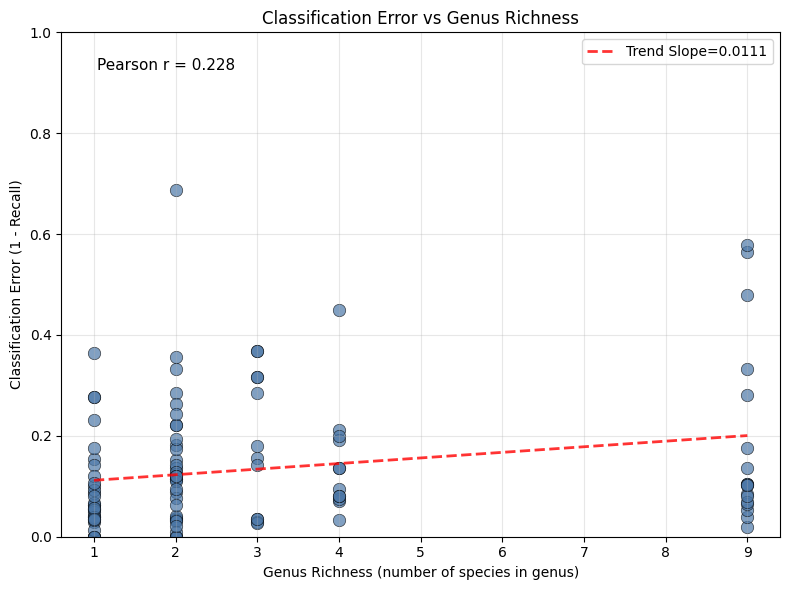

In [8]:
if "GATED" in MODELS:
    df = predictions["GATED"]
    per_species = pd.DataFrame({"species": sorted(df["species"].unique())})
    per_species["error"] = [
        1 - recall_score(df["species"] == sp, df["species_pred"] == sp, zero_division=0) for sp in per_species["species"]
    ]
    species_genus = test[["species", "genus"]].drop_duplicates()
    richness = species_genus.groupby("genus")["species"].nunique()
    plot_df = per_species.merge(species_genus, on="species")
    plot_df["genus_richness"] = plot_df["genus"].map(richness)

    r = plot_df["genus_richness"].corr(plot_df["error"])
    slope, intercept = np.polyfit(plot_df["genus_richness"], plot_df["error"], 1)
    print(f"Pearson r = {r:.3f}, slope = {slope:.4f}")
    xs = np.linspace(plot_df["genus_richness"].min(), plot_df["genus_richness"].max(), 50)

    plt.figure(figsize=(8, 6))
    plt.scatter(plot_df["genus_richness"], plot_df["error"], alpha=0.7, s=80, color="#4C78A8", edgecolors="black", linewidth=0.5)
    plt.plot(xs, slope * xs + intercept, "r--", linewidth=2, alpha=0.8, label=f"Trend Slope={slope:.4f}")
    plt.annotate(f"Pearson r = {r:.3f}", xy=(0.05, 0.95), xycoords="axes fraction", ha="left", va="top", fontsize=11)
    plt.xlabel("Genus Richness (number of species in genus)")
    plt.ylabel("Classification Error (1 - Recall)")
    plt.title("Classification Error vs Genus Richness")
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Needs the GATED model.")

## Saliency maps (GATED)

Original photo, species-level saliency map and overlay for each image in `images/`. Saliency uses random smoothing noise, so maps vary slightly between runs.

lab_Eviota_albolineata_sample.jpg ('Gobiidae', 'Eviota', 'Eviota albolineata')
lab_Eviota_infulata_sample.jpg ('Gobiidae', 'Eviota', 'Eviota infulata')
lab_Eviota_teresae_sample.jpg ('Gobiidae', 'Eviota', 'Eviota teresae')


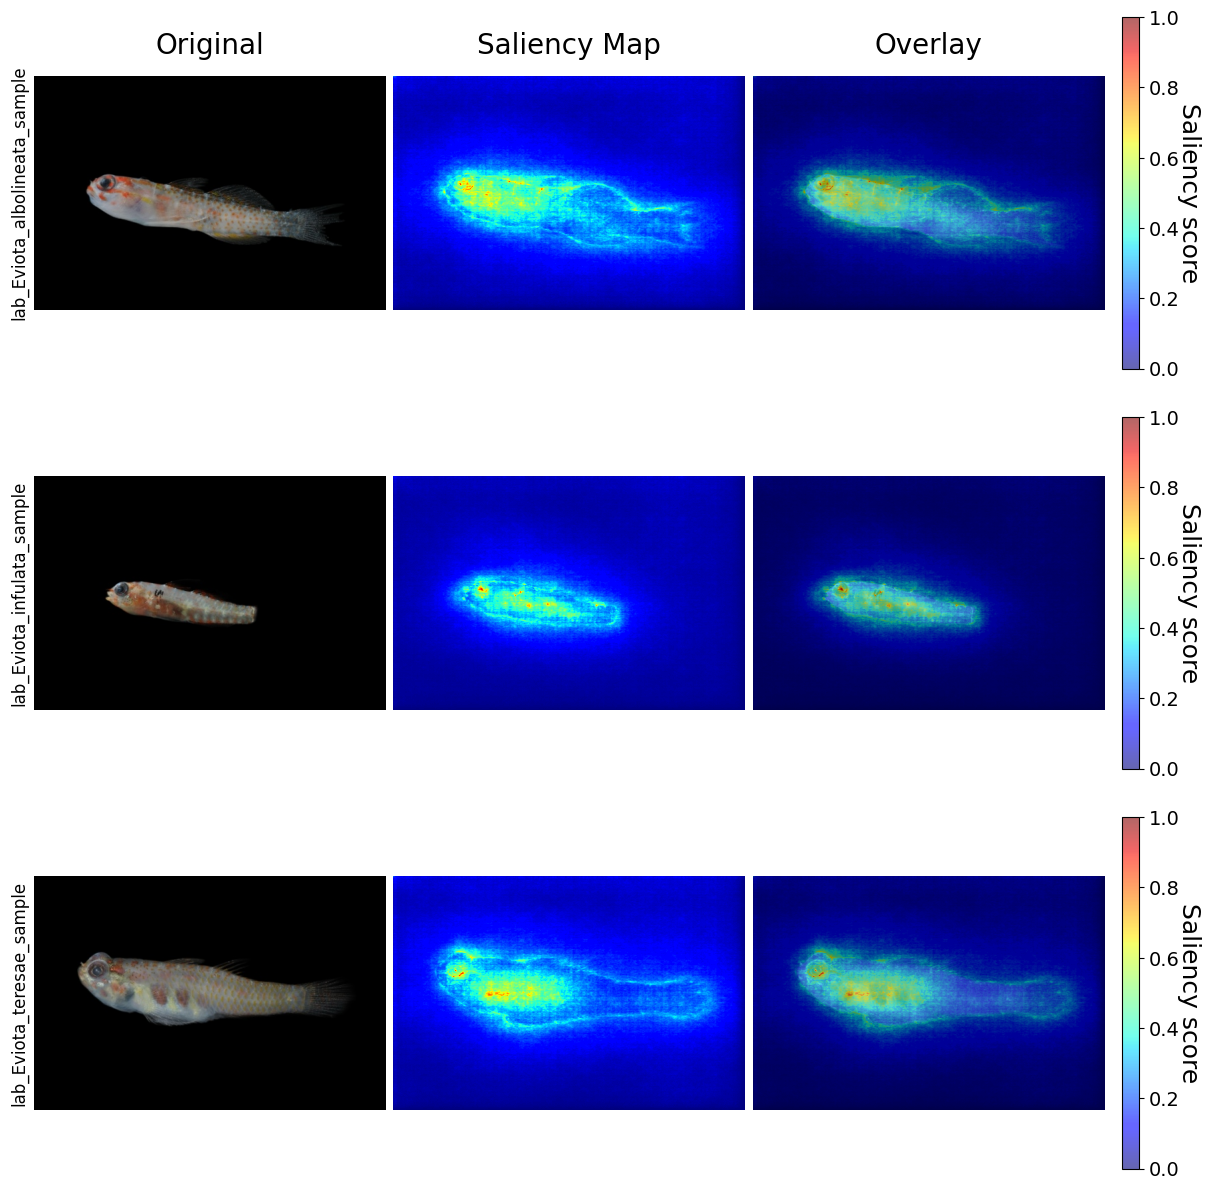

In [9]:
images = sorted(p for p in SALIENCY_DIR.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
if images and "GATED" in MODELS:
    ai = CryptoVisionAI(load_pretrained("gated"), names["family"], names["genus"], names["species"])
    fig, axes = plt.subplots(len(images), 3, figsize=(12, 4 * len(images)), constrained_layout=True, squeeze=False)
    for ax, title in zip(axes[0], ["Original", "Saliency Map", "Overlay"]):
        ax.set_title(title, fontsize=20, pad=16)

    for row, img_path in enumerate(images):
        pil_img = Image.open(img_path).convert("RGB")
        w, h = pil_img.size
        print(img_path.name, ai.predict(str(img_path)))
        sal = ai.generate_saliency_map("species", 100, 0.2)[0]
        sal_big = np.array(Image.fromarray((sal * 255).astype("uint8")).resize((w, h), Image.Resampling.BILINEAR)) / 255.0

        axes[row, 0].imshow(pil_img)
        axes[row, 0].set_ylabel(img_path.stem, fontsize=12)
        axes[row, 1].imshow(sal_big, cmap="jet", vmin=0, vmax=1, aspect="equal")
        axes[row, 2].imshow(pil_img.convert("L"), cmap="gray", vmin=0, vmax=255, aspect="equal")
        im = axes[row, 2].imshow(sal_big, cmap="jet", alpha=0.6, vmin=0, vmax=1, aspect="equal")
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
            ax.spines[:].set_visible(False)
        cbar = fig.colorbar(im, ax=axes[row, 2], fraction=0.05, pad=0.05, ticks=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
        cbar.ax.tick_params(labelsize=14)
        cbar.set_label("Saliency score", rotation=270, labelpad=15, fontsize=18)

    plt.show()
else:
    print(f"Needs the GATED model and images in {SALIENCY_DIR}/.")